In [ ]:
# CSET485 – AI and Society
## Assignment #1 – German Credit Data Analysis

**Roll Number:** 0133  
**Dataset:** Statlog German Credit Data  
**Random State:** 133  
**Train-Test Split:** 70% Train / 30% Test

### Objective
This assignment investigates predictive modeling, statistical stress-testing,
adversarial cases, and fairness trade-offs using the German Credit dataset.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
# Assignment configuration

ROLL_NUMBER = "0133"
RANDOM_STATE = 133
TEST_SIZE = 0.30

print("Roll Number:", ROLL_NUMBER)
print("Random State:", RANDOM_STATE)
print("Test Size:", TEST_SIZE)

Roll Number: 0133
Random State: 133
Test Size: 0.3


In [5]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

df = pd.read_csv(
    url,
    sep=r"\s+",
    header=None
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 21)


In [6]:
column_names = [
    "checking_status",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_status",
    "employment",
    "installment_rate",
    "personal_status",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "num_dependents",
    "telephone",
    "foreign_worker",
    "credit_risk"
]

df.columns = column_names

print("Column names assigned successfully.")

Column names assigned successfully.


In [7]:
print("Dataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape:
(1000, 21)

First 5 Rows:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [8]:
print("Dataset Information:\n")

df.info()

Dataset Information:

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   checking_status          1000 non-null   str  
 1   duration                 1000 non-null   int64
 2   credit_history           1000 non-null   str  
 3   purpose                  1000 non-null   str  
 4   credit_amount            1000 non-null   int64
 5   savings_status           1000 non-null   str  
 6   employment               1000 non-null   str  
 7   installment_rate         1000 non-null   int64
 8   personal_status          1000 non-null   str  
 9   other_debtors            1000 non-null   str  
 10  residence_since          1000 non-null   int64
 11  property                 1000 non-null   str  
 12  age                      1000 non-null   int64
 13  other_installment_plans  1000 non-null   str  
 14  housing                  1000 non-null   str  

In [9]:
print("Statistical Summary:")

display(df.describe(include="all").T)

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
checking_status,1000,4,A14,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
credit_history,1000,5,A32,530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purpose,1000,10,A43,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
savings_status,1000,5,A61,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment,1000,5,A73,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
installment_rate,1000.0,NaN,NaN,NaN,2.973,1.118715,1.0,2.0,3.0,4.0,4.0
personal_status,1000,4,A93,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
other_debtors,1000,3,A101,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
print("Target Distribution:")

print(df["credit_risk"].value_counts())

Target Distribution:
credit_risk
1    700
2    300
Name: count, dtype: int64


In [12]:
## 2.1 Missing Value Analysis

##Before preprocessing the dataset, we check for missing values in every feature. 
##This determines whether imputation or another missing-value treatment is required.

In [13]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:


checking_status            0
duration                   0
credit_history             0
purpose                    0
credit_amount              0
savings_status             0
employment                 0
installment_rate           0
personal_status            0
other_debtors              0
residence_since            0
property                   0
age                        0
other_installment_plans    0
housing                    0
existing_credits           0
job                        0
num_dependents             0
telephone                  0
foreign_worker             0
credit_risk                0
dtype: int64


Total missing values: 0


In [14]:
print("Unique target values:")
print(df["credit_risk"].unique())

print("\nTarget distribution:")
print(df["credit_risk"].value_counts())

Unique target values:
[1 2]

Target distribution:
credit_risk
1    700
2    300
Name: count, dtype: int64


In [15]:
## 2.2 Target Encoding

#The original German Credit dataset represents credit risk using:
#- 1 = Good credit
#- 2 = Bad credit

#For this assignment, the target is converted to:
#- 1 = Approve
#- 0 = Reject

In [16]:
# Convert target to assignment format
df["credit_risk"] = df["credit_risk"].map({
    1: 1,
    2: 0
})

print("Encoded target distribution:")
print(df["credit_risk"].value_counts())

Encoded target distribution:
credit_risk
1    700
0    300
Name: count, dtype: int64


In [17]:
X = df.drop("credit_risk", axis=1)
y = df["credit_risk"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1000, 20)
Target shape: (1000,)


In [18]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Categorical Features:
['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


In [19]:
for column in categorical_features:
    print(f"\n{column}")
    print(X[column].value_counts())


checking_status
checking_status
A14    394
A11    274
A12    269
A13     63
Name: count, dtype: int64

credit_history
credit_history
A32    530
A34    293
A33     88
A31     49
A30     40
Name: count, dtype: int64

purpose
purpose
A43     280
A40     234
A42     181
A41     103
A49      97
A46      50
A45      22
A44      12
A410     12
A48       9
Name: count, dtype: int64

savings_status
savings_status
A61    603
A65    183
A62    103
A63     63
A64     48
Name: count, dtype: int64

employment
employment
A73    339
A75    253
A74    174
A72    172
A71     62
Name: count, dtype: int64

personal_status
personal_status
A93    548
A92    310
A94     92
A91     50
Name: count, dtype: int64

other_debtors
other_debtors
A101    907
A103     52
A102     41
Name: count, dtype: int64

property
property
A123    332
A121    282
A122    232
A124    154
Name: count, dtype: int64

other_installment_plans
other_installment_plans
A143    814
A141    139
A142     47
Name: count, dtype: int64

housing

In [20]:
display(X[numerical_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
num_dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


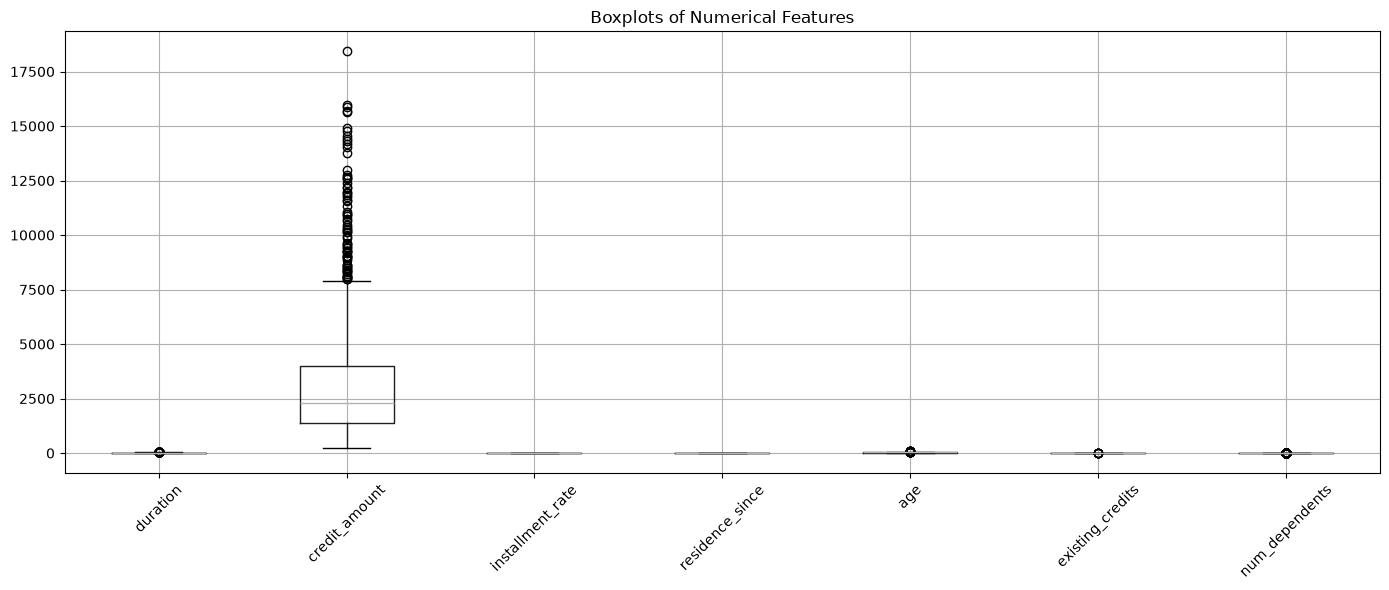

In [21]:
plt.figure(figsize=(14, 6))

X[numerical_features].boxplot()

plt.xticks(rotation=45)
plt.title("Boxplots of Numerical Features")
plt.tight_layout()
plt.show()

In [22]:
## 2.3 Train-Test Split

#The dataset is divided into 70% training data and 30% testing data using
#the last three digits of the roll number, 133, as the random seed.

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=133,
    stratify=y
)

print("Training set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training set:
X_train: (700, 20)
y_train: (700,)

Testing set:
X_test: (300, 20)
y_test: (300,)


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [25]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

In [26]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (700, 61)
Processed testing shape: (300, 61)


In [27]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))

print("\nFirst 20 processed features:")
print(feature_names[:20])

Number of processed features: 61

First 20 processed features:
['num__duration' 'num__credit_amount' 'num__installment_rate'
 'num__residence_since' 'num__age' 'num__existing_credits'
 'num__num_dependents' 'cat__checking_status_A11'
 'cat__checking_status_A12' 'cat__checking_status_A13'
 'cat__checking_status_A14' 'cat__credit_history_A30'
 'cat__credit_history_A31' 'cat__credit_history_A32'
 'cat__credit_history_A33' 'cat__credit_history_A34' 'cat__purpose_A40'
 'cat__purpose_A41' 'cat__purpose_A410' 'cat__purpose_A42']


In [28]:
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed training data:")
display(X_train_processed_df.head())

Processed training data:


,num__duration,num__credit_amount,num__installment_rate,num__residence_since,num__age,num__existing_credits,num__num_dependents,cat__checking_status_A11,cat__checking_status_A12,cat__checking_status_A13,...,cat__housing_A152,cat__housing_A153,cat__job_A171,cat__job_A172,cat__job_A173,cat__job_A174,cat__telephone_A191,cat__telephone_A192,cat__foreign_worker_A201,cat__foreign_worker_A202
371,-0.244742,0.949331,0.016651,1.043876,-0.217804,1.016398,-0.417728,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
316,-0.741559,-0.895165,-0.879952,0.140646,0.214101,-0.727422,2.393903,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
171,-0.741559,-0.876245,0.913254,-1.665815,-0.822471,-0.727422,-0.417728,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
438,1.742527,0.028803,0.913254,1.043876,2.546389,1.016398,-0.417728,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
650,2.239345,1.432987,0.913254,-1.665815,1.250674,-0.727422,-0.417728,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0


In [29]:
# Phase 3 – Model Building

#In this phase, two predictive models are trained on the preprocessed
#German Credit dataset:

#1. Linear Regression (OLS)
#2. Logistic Regression

#Both models use the same training and testing datasets.

In [30]:
from sklearn.linear_model import LinearRegression, LogisticRegression

In [31]:
print("Training data shape:", X_train_processed_df.shape)
print("Testing data shape:", X_test_processed_df.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (700, 61)
Testing data shape: (300, 61)

Training target shape: (700,)
Testing target shape: (300,)


In [32]:
## 3.1 Model A – Linear Regression (OLS)

#Linear Regression is used to predict the binary credit approval outcome
#as a continuous value. The resulting predictions are interpreted as
#probability-like scores and will later be thresholded using the median
#predicted value as required by the assignment.

In [33]:
# Create Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(
    X_train_processed_df,
    y_train
)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [34]:
# Predict on test data
linear_predictions = linear_model.predict(
    X_test_processed_df
)

print("First 10 Linear Regression predictions:")
print(linear_predictions[:10])

First 10 Linear Regression predictions:
[1.08302738 1.05617868 0.91063449 0.39032045 0.71369647 0.86192139
 0.17238657 0.43226778 0.8431478  0.60055292]


In [35]:
print("Minimum prediction:", linear_predictions.min())
print("Maximum prediction:", linear_predictions.max())
print("Mean prediction:", linear_predictions.mean())
print("Median prediction:", np.median(linear_predictions))

Minimum prediction: -0.0007084838364763701
Maximum prediction: 1.2721204445520777
Mean prediction: 0.6992698080788693
Median prediction: 0.7160113795344428


In [36]:
linear_median = np.median(linear_predictions)

print("Median Linear Regression prediction:", linear_median)

Median Linear Regression prediction: 0.7160113795344428


In [37]:
## 3.2 Model B – Logistic Regression

#Logistic Regression is trained to predict the probability that an applicant
#belongs to the approval class (1). The classification threshold will later
#be set to 0.5 as specified in the assignment.

In [38]:
# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=133
)

# Train the model
logistic_model.fit(
    X_train_processed_df,
    y_train
)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [39]:
logistic_probabilities = logistic_model.predict_proba(
    X_test_processed_df
)[:, 1]

print("First 10 Logistic Regression probabilities:")
print(logistic_probabilities[:10])

First 10 Logistic Regression probabilities:
[0.98049817 0.97343066 0.91166798 0.30769422 0.82314093 0.90463037
 0.13516907 0.37797423 0.86859498 0.67582358]


In [40]:
print("Minimum probability:", logistic_probabilities.min())
print("Maximum probability:", logistic_probabilities.max())
print("Mean probability:", logistic_probabilities.mean())
print("Median probability:", np.median(logistic_probabilities))

Minimum probability: 0.04426024081978929
Maximum probability: 0.9924842325455513
Mean probability: 0.6949500645158978
Median probability: 0.7899653822918817


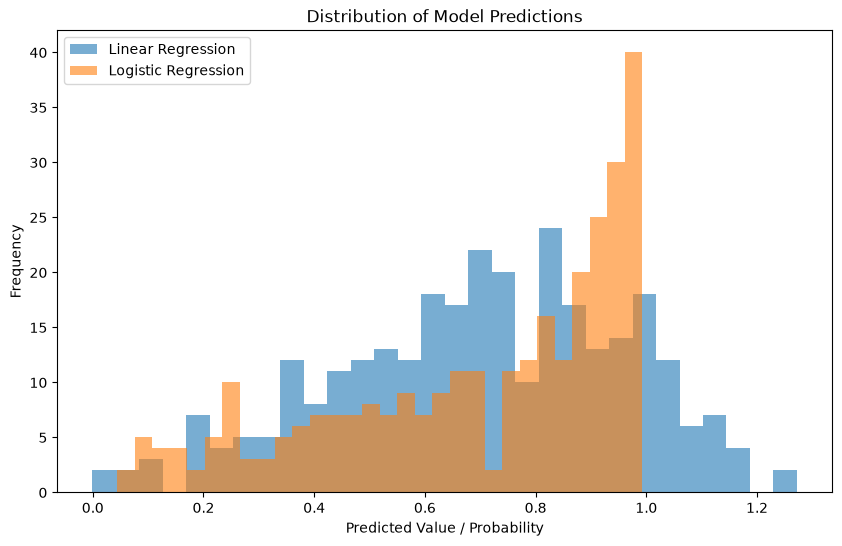

In [41]:
plt.figure(figsize=(10, 6))

plt.hist(
    linear_predictions,
    bins=30,
    alpha=0.6,
    label="Linear Regression"
)

plt.hist(
    logistic_probabilities,
    bins=30,
    alpha=0.6,
    label="Logistic Regression"
)

plt.xlabel("Predicted Value / Probability")
plt.ylabel("Frequency")
plt.title("Distribution of Model Predictions")
plt.legend()
plt.show()

In [42]:
# Phase 4 – Model Comparison and Mismatch Analysis

#The Linear Regression predictions are converted into binary classifications
#using the median predicted value as the threshold, as specified in the
#assignment.

In [43]:
# Classify Linear Regression predictions using the median threshold

linear_classifications = (
    linear_predictions >= linear_median
).astype(int)

print("Linear Regression classification counts:")
print(pd.Series(linear_classifications).value_counts())

Linear Regression classification counts:
1    150
0    150
Name: count, dtype: int64


In [44]:
# Classify Logistic Regression probabilities using threshold = 0.5

logistic_classifications = (
    logistic_probabilities >= 0.5
).astype(int)

print("Logistic Regression classification counts:")
print(pd.Series(logistic_classifications).value_counts())

Logistic Regression classification counts:
1    226
0     74
Name: count, dtype: int64


In [45]:
comparison_df = pd.DataFrame({
    "Actual": y_test.values,
    "Linear_Prediction": linear_predictions,
    "Linear_Class": linear_classifications,
    "Logistic_Probability": logistic_probabilities,
    "Logistic_Class": logistic_classifications
})

display(comparison_df.head(10))

,Actual,Linear_Prediction,Linear_Class,Logistic_Probability,Logistic_Class
0,1,1.083027,1,0.980498,1
1,1,1.056179,1,0.973431,1
2,1,0.910634,1,0.911668,1
3,0,0.390320,0,0.307694,0
4,0,0.713696,0,0.823141,1
5,1,0.861921,1,0.904630,1
6,0,0.172387,0,0.135169,0
7,0,0.432268,0,0.377974,0
8,1,0.843148,1,0.868595,1
9,1,0.600553,0,0.675824,1


In [46]:
comparison_df["Mismatch"] = (
    comparison_df["Linear_Class"] != comparison_df["Logistic_Class"]
)

mismatch_count = comparison_df["Mismatch"].sum()
total_test_cases = len(comparison_df)

mismatch_percentage = (
    mismatch_count / total_test_cases
) * 100

print("Total test cases:", total_test_cases)
print("Mismatched cases:", mismatch_count)
print("Mismatch percentage:", mismatch_percentage)

Total test cases: 300
Mismatched cases: 76
Mismatch percentage: 25.333333333333336


In [47]:
cm_models = confusion_matrix(
    linear_classifications,
    logistic_classifications
)

print("Confusion Matrix:")
print(cm_models)

Confusion Matrix:
[[ 74  76]
 [  0 150]]


In [48]:
cm_df = pd.DataFrame(
    cm_models,
    index=["Linear = 0", "Linear = 1"],
    columns=["Logistic = 0", "Logistic = 1"]
)

display(cm_df)

,Logistic = 0,Logistic = 1
Linear = 0,74,76
Linear = 1,0,150


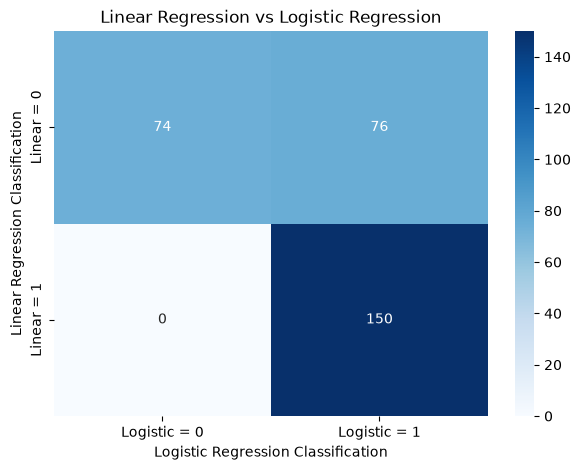

In [49]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Linear Regression vs Logistic Regression")
plt.xlabel("Logistic Regression Classification")
plt.ylabel("Linear Regression Classification")

plt.show()

In [50]:
mismatched_cases = comparison_df[
    comparison_df["Mismatch"] == True
]

print("Number of mismatched cases:", len(mismatched_cases))

display(mismatched_cases.head(10))

Number of mismatched cases: 76


,Actual,Linear_Prediction,Linear_Class,Logistic_Probability,Logistic_Class,Mismatch
4,0,0.713696,0,0.823141,1,True
9,1,0.600553,0,0.675824,1,True
13,1,0.669499,0,0.684444,1,True
25,1,0.709338,0,0.747464,1,True
32,1,0.675899,0,0.680207,1,True
33,1,0.690342,0,0.753050,1,True
38,1,0.698930,0,0.755638,1,True
46,1,0.666004,0,0.625516,1,True
47,1,0.648158,0,0.667917,1,True
50,0,0.572575,0,0.534212,1,True


In [51]:
# Phase 5 – Simpson's Paradox Hunt

#The purpose of this analysis is to investigate whether the relationship
#between a predictor and credit approval changes substantially across
#demographic/social subgroups.

#We will first inspect potential subgroup variables before selecting the
#most appropriate two-group comparison.

In [52]:
# Inspect potential demographic/social variables

print("Personal status and sex:")
print(df["personal_status"].value_counts())

print("\nAge statistics:")
print(df["age"].describe())

Personal status and sex:
personal_status
A93    548
A92    310
A94     92
A91     50
Name: count, dtype: int64

Age statistics:
count    1000.000000
mean       35.546000
std        11.375469
min        19.000000
25%        27.000000
50%        33.000000
75%        42.000000
max        75.000000
Name: age, dtype: float64


In [53]:
print("Unique personal-status categories:")
print(sorted(df["personal_status"].unique()))

Unique personal-status categories:
['A91', 'A92', 'A93', 'A94']


In [54]:
group_counts = df["personal_status"].value_counts()

print("Group sizes:")
display(group_counts)

Group sizes:


personal_status
A93    548
A92    310
A94     92
A91     50
Name: count, dtype: int64

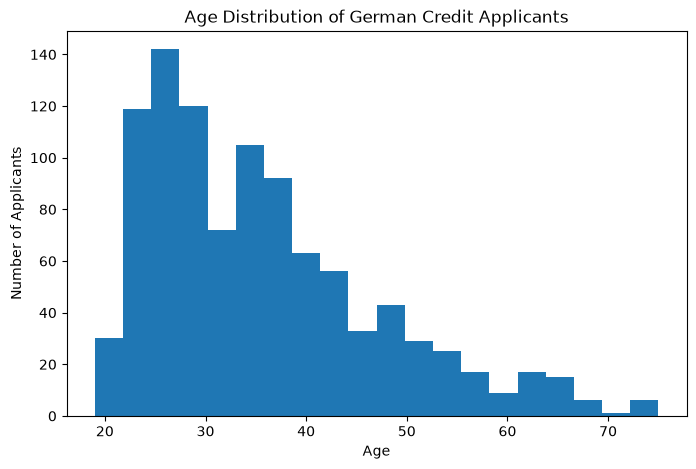

In [55]:
plt.figure(figsize=(8, 5))

plt.hist(df["age"], bins=20)

plt.xlabel("Age")
plt.ylabel("Number of Applicants")
plt.title("Age Distribution of German Credit Applicants")

plt.show()

In [56]:
print("Age median:", df["age"].median())
print("Age mean:", df["age"].mean())

Age median: 33.0
Age mean: 35.546


In [57]:
age_median = df["age"].median()

df["age_group"] = np.where(
    df["age"] < age_median,
    "Below_Median_Age",
    "At_or_Above_Median_Age"
)

print("Age median:", age_median)

print("\nAge group counts:")
print(df["age_group"].value_counts())

Age median: 33.0

Age group counts:
age_group
At_or_Above_Median_Age    517
Below_Median_Age          483
Name: count, dtype: int64


In [58]:
age_group_approval = (
    df.groupby("age_group")["credit_risk"]
    .agg(["count", "mean"])
)

age_group_approval["approval_percentage"] = (
    age_group_approval["mean"] * 100
)

display(age_group_approval)

,count,mean,approval_percentage
age_group,,,
At_or_Above_Median_Age,517,0.744681,74.468085
Below_Median_Age,483,0.652174,65.217391


In [59]:
print(
    df.groupby("age_group")["duration"]
    .agg(["count", "mean", "median"])
)

                        count       mean  median
age_group                                       
At_or_Above_Median_Age    517  20.512573    18.0
Below_Median_Age          483  21.320911    18.0


In [60]:
print(
    df.groupby("age_group")["credit_risk"]
    .mean()
)

age_group
At_or_Above_Median_Age    0.744681
Below_Median_Age          0.652174
Name: credit_risk, dtype: float64


In [61]:
# Phase 5.8 - Prepare age-based groups for logistic regression

# Add age_group to the training data using the original indices
train_analysis = df.loc[X_train.index].copy()

# Create the same age groups
train_analysis["age_group"] = np.where(
    train_analysis["age"] < age_median,
    "Below_Median_Age",
    "At_or_Above_Median_Age"
)

# Separate groups
group_below = train_analysis[
    train_analysis["age_group"] == "Below_Median_Age"
]

group_above = train_analysis[
    train_analysis["age_group"] == "At_or_Above_Median_Age"
]

print("Full training dataset:", train_analysis.shape)
print("Below median age:", group_below.shape)
print("At/above median age:", group_above.shape)

Full training dataset: (700, 22)
Below median age: (347, 22)
At/above median age: (353, 22)


In [62]:
# Phase 5.9 - Transform the three groups using the existing preprocessor

# Features and target
X_full_analysis = train_analysis.drop(
    columns=["credit_risk", "age_group"]
)
y_full_analysis = train_analysis["credit_risk"]

X_below = group_below.drop(
    columns=["credit_risk", "age_group"]
)
y_below = group_below["credit_risk"]

X_above = group_above.drop(
    columns=["credit_risk", "age_group"]
)
y_above = group_above["credit_risk"]

# Transform using the SAME preprocessor from Phase 2
X_full_processed = preprocessor.transform(X_full_analysis)
X_below_processed = preprocessor.transform(X_below)
X_above_processed = preprocessor.transform(X_above)

# Convert to DataFrames
X_full_processed_df = pd.DataFrame(
    X_full_processed,
    columns=feature_names,
    index=X_full_analysis.index
)

X_below_processed_df = pd.DataFrame(
    X_below_processed,
    columns=feature_names,
    index=X_below.index
)

X_above_processed_df = pd.DataFrame(
    X_above_processed,
    columns=feature_names,
    index=X_above.index
)

print("Full:", X_full_processed_df.shape)
print("Below:", X_below_processed_df.shape)
print("Above:", X_above_processed_df.shape)

Full: (700, 61)
Below: (347, 61)
Above: (353, 61)


In [63]:
# Phase 5.9 - Transform the three groups using the existing preprocessor

# Features and target
X_full_analysis = train_analysis.drop(
    columns=["credit_risk", "age_group"]
)
y_full_analysis = train_analysis["credit_risk"]

X_below = group_below.drop(
    columns=["credit_risk", "age_group"]
)
y_below = group_below["credit_risk"]

X_above = group_above.drop(
    columns=["credit_risk", "age_group"]
)
y_above = group_above["credit_risk"]

# Transform using the SAME preprocessor from Phase 2
X_full_processed = preprocessor.transform(X_full_analysis)
X_below_processed = preprocessor.transform(X_below)
X_above_processed = preprocessor.transform(X_above)

# Convert to DataFrames
X_full_processed_df = pd.DataFrame(
    X_full_processed,
    columns=feature_names,
    index=X_full_analysis.index
)

X_below_processed_df = pd.DataFrame(
    X_below_processed,
    columns=feature_names,
    index=X_below.index
)

X_above_processed_df = pd.DataFrame(
    X_above_processed,
    columns=feature_names,
    index=X_above.index
)

print("Full:", X_full_processed_df.shape)
print("Below:", X_below_processed_df.shape)
print("Above:", X_above_processed_df.shape)

Full: (700, 61)
Below: (347, 61)
Above: (353, 61)


In [64]:
# Phase 5.10 - Logistic regression models

logistic_full = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

logistic_below = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

logistic_above = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

# Fit models
logistic_full.fit(
    X_full_processed_df,
    y_full_analysis
)

logistic_below.fit(
    X_below_processed_df,
    y_below
)

logistic_above.fit(
    X_above_processed_df,
    y_above
)

print("All three logistic regression models fitted successfully.")

All three logistic regression models fitted successfully.


In [65]:
# Phase 5.11 - Compare duration coefficients

duration_feature = "num__duration"

duration_index = list(feature_names).index(duration_feature)

duration_comparison = pd.DataFrame({
    "Model": [
        "Full Dataset",
        "Below Median Age",
        "At/Above Median Age"
    ],
    "Duration_Coefficient": [
        logistic_full.coef_[0][duration_index],
        logistic_below.coef_[0][duration_index],
        logistic_above.coef_[0][duration_index]
    ]
})

display(duration_comparison)

,Model,Duration_Coefficient
0,Full Dataset,-0.317087
1,Below Median Age,-0.426413
2,At/Above Median Age,-0.247594


In [66]:
# Phase 5.12 - Compare all coefficients

coefficient_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Full_Dataset": logistic_full.coef_[0],
    "Below_Median_Age": logistic_below.coef_[0],
    "At_or_Above_Median_Age": logistic_above.coef_[0]
})

# Add sign-change indicators
coefficient_comparison["Sign_Change_Below"] = (
    np.sign(coefficient_comparison["Full_Dataset"]) !=
    np.sign(coefficient_comparison["Below_Median_Age"])
)

coefficient_comparison["Sign_Change_Above"] = (
    np.sign(coefficient_comparison["Full_Dataset"]) !=
    np.sign(coefficient_comparison["At_or_Above_Median_Age"])
)

display(coefficient_comparison)

,Feature,Full_Dataset,Below_Median_Age,At_or_Above_Median_Age,Sign_Change_Below,Sign_Change_Above
0,num__duration,-0.317087,-0.426413,-0.247594,False,False
1,num__credit_amount,-0.331556,-0.249257,-0.355817,False,False
2,num__installment_rate,-0.304241,-0.292331,-0.382746,False,False
3,num__residence_since,0.025603,-0.157130,0.165440,True,False
4,num__age,0.462299,0.903968,0.493684,False,False
...,...,...,...,...,...,...
56,cat__job_A174,0.071414,0.198495,-0.072313,False,True
57,cat__telephone_A191,-0.066340,0.143608,-0.292489,True,False
58,cat__telephone_A192,0.062806,-0.144809,0.295344,True,False
59,cat__foreign_worker_A201,-0.521799,-0.539272,-0.295630,False,False


In [67]:
# Possible Simpson's Paradox candidates

sign_changes = coefficient_comparison[
    (coefficient_comparison["Sign_Change_Below"]) |
    (coefficient_comparison["Sign_Change_Above"])
]

display(sign_changes)

,Feature,Full_Dataset,Below_Median_Age,At_or_Above_Median_Age,Sign_Change_Below,Sign_Change_Above
3,num__residence_since,0.025603,-0.157130,0.165440,True,False
5,num__existing_credits,-0.123625,-0.246448,0.046906,False,True
6,num__num_dependents,-0.100966,0.025709,-0.236239,True,False
14,cat__credit_history_A33,0.225732,-0.181714,0.498339,True,False
18,cat__purpose_A410,0.461432,-0.262221,0.582237,True,False
20,cat__purpose_A43,0.072407,0.236652,-0.009985,False,True
24,cat__purpose_A48,0.272492,-0.261644,0.703188,True,False
25,cat__purpose_A49,0.148397,0.436498,-0.121106,False,True
27,cat__savings_status_A62,-0.145425,-0.096312,0.154320,False,True
30,cat__savings_status_A65,0.069746,0.311376,-0.148148,False,True


In [72]:
# Phase 5.13 – Statistical Logistic Regression for Simpson's Paradox

import statsmodels.api as sm
import pandas as pd
import numpy as np

# Predictors selected for the statistical analysis
candidate_predictors = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "num_dependents"
]

# Make sure required columns exist
required_columns = candidate_predictors + ["credit_risk", "age_group"]

missing_columns = [
    col for col in required_columns
    if col not in train_analysis.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Function to fit a stable logistic regression
def fit_logit(data, predictors):
    X = data[predictors].copy()
    y = data["credit_risk"].astype(int)

    # Remove rows with missing values
    valid = X.notna().all(axis=1) & y.notna()

    X = X.loc[valid]
    y = y.loc[valid]

    # Add intercept
    X = sm.add_constant(X, has_constant="add")

    model = sm.Logit(y, X)
    result = model.fit(disp=False, maxiter=200)

    return result


# Full training dataset
full_result = fit_logit(
    train_analysis,
    candidate_predictors
)

# Below-median age group
below_result = fit_logit(
    train_analysis[
        train_analysis["age_group"] == "Below_Median_Age"
    ],
    candidate_predictors
)

# At-or-above-median age group
above_result = fit_logit(
    train_analysis[
        train_analysis["age_group"] == "At_or_Above_Median_Age"
    ],
    candidate_predictors
)


# Collect statistical results
results = []

for predictor in candidate_predictors:

    results.append({
        "Predictor": predictor,

        "Full_Coefficient": full_result.params[predictor],
        "Full_P_Value": full_result.pvalues[predictor],
        "Full_CI_Lower": full_result.conf_int().loc[predictor, 0],
        "Full_CI_Upper": full_result.conf_int().loc[predictor, 1],

        "Below_Coefficient": below_result.params[predictor],
        "Below_P_Value": below_result.pvalues[predictor],
        "Below_CI_Lower": below_result.conf_int().loc[predictor, 0],
        "Below_CI_Upper": below_result.conf_int().loc[predictor, 1],

        "Above_Coefficient": above_result.params[predictor],
        "Above_P_Value": above_result.pvalues[predictor],
        "Above_CI_Lower": above_result.conf_int().loc[predictor, 0],
        "Above_CI_Upper": above_result.conf_int().loc[predictor, 1]
    })


candidate_stats = pd.DataFrame(results)

display(candidate_stats)

,Predictor,Full_Coefficient,Full_P_Value,Full_CI_Lower,Full_CI_Upper,Below_Coefficient,Below_P_Value,Below_CI_Lower,Below_CI_Upper,Above_Coefficient,Above_P_Value,Above_CI_Lower,Above_CI_Upper
0,duration,-0.025458,0.005301,-0.043354,-0.007562,-0.032822,0.011909,-0.058402,-0.007242,-0.019395,0.140551,-0.045188,0.006399
1,credit_amount,-0.000080,0.038962,-0.000156,-0.000004,-0.000071,0.191418,-0.000178,0.000036,-0.000098,0.083282,-0.000209,0.000013
2,installment_rate,-0.150209,0.080177,-0.318474,0.018055,-0.210604,0.065748,-0.434922,0.013714,-0.190640,0.173538,-0.465194,0.083914
3,residence_since,-0.054215,0.500480,-0.211933,0.103503,-0.112018,0.300013,-0.323857,0.099821,0.107224,0.400798,-0.142902,0.357349
4,age,0.037532,0.000029,0.019943,0.055121,0.115971,0.003049,0.039253,0.192689,0.010378,0.484134,-0.018694,0.039451
5,existing_credits,0.143171,0.371107,-0.170569,0.456912,-0.170930,0.486474,-0.652325,0.310466,0.345948,0.122560,-0.093167,0.785063
6,num_dependents,-0.052120,0.835498,-0.544051,0.439812,0.307865,0.532855,-0.659666,1.275396,-0.450384,0.145338,-1.056577,0.155808


In [73]:
print(type(candidate_stats))
print(candidate_stats.shape)
display(candidate_stats)

<class 'pandas.DataFrame'>
(7, 13)


,Predictor,Full_Coefficient,Full_P_Value,Full_CI_Lower,Full_CI_Upper,Below_Coefficient,Below_P_Value,Below_CI_Lower,Below_CI_Upper,Above_Coefficient,Above_P_Value,Above_CI_Lower,Above_CI_Upper
0,duration,-0.025458,0.005301,-0.043354,-0.007562,-0.032822,0.011909,-0.058402,-0.007242,-0.019395,0.140551,-0.045188,0.006399
1,credit_amount,-0.000080,0.038962,-0.000156,-0.000004,-0.000071,0.191418,-0.000178,0.000036,-0.000098,0.083282,-0.000209,0.000013
2,installment_rate,-0.150209,0.080177,-0.318474,0.018055,-0.210604,0.065748,-0.434922,0.013714,-0.190640,0.173538,-0.465194,0.083914
3,residence_since,-0.054215,0.500480,-0.211933,0.103503,-0.112018,0.300013,-0.323857,0.099821,0.107224,0.400798,-0.142902,0.357349
4,age,0.037532,0.000029,0.019943,0.055121,0.115971,0.003049,0.039253,0.192689,0.010378,0.484134,-0.018694,0.039451
5,existing_credits,0.143171,0.371107,-0.170569,0.456912,-0.170930,0.486474,-0.652325,0.310466,0.345948,0.122560,-0.093167,0.785063
6,num_dependents,-0.052120,0.835498,-0.544051,0.439812,0.307865,0.532855,-0.659666,1.275396,-0.450384,0.145338,-1.056577,0.155808


In [74]:
# Phase 5.14 - Rounded statistical results

candidate_stats_rounded = candidate_stats.copy()

numeric_columns = candidate_stats_rounded.select_dtypes(
    include=["float64", "float32"]
).columns

candidate_stats_rounded[numeric_columns] = (
    candidate_stats_rounded[numeric_columns].round(4)
)

display(candidate_stats_rounded)

,Predictor,Full_Coefficient,Full_P_Value,Full_CI_Lower,Full_CI_Upper,Below_Coefficient,Below_P_Value,Below_CI_Lower,Below_CI_Upper,Above_Coefficient,Above_P_Value,Above_CI_Lower,Above_CI_Upper
0,duration,-0.0255,0.0053,-0.0434,-0.0076,-0.0328,0.0119,-0.0584,-0.0072,-0.0194,0.1406,-0.0452,0.0064
1,credit_amount,-0.0001,0.0390,-0.0002,-0.0000,-0.0001,0.1914,-0.0002,0.0000,-0.0001,0.0833,-0.0002,0.0000
2,installment_rate,-0.1502,0.0802,-0.3185,0.0181,-0.2106,0.0657,-0.4349,0.0137,-0.1906,0.1735,-0.4652,0.0839
3,residence_since,-0.0542,0.5005,-0.2119,0.1035,-0.1120,0.3000,-0.3239,0.0998,0.1072,0.4008,-0.1429,0.3573
4,age,0.0375,0.0000,0.0199,0.0551,0.1160,0.0030,0.0393,0.1927,0.0104,0.4841,-0.0187,0.0395
5,existing_credits,0.1432,0.3711,-0.1706,0.4569,-0.1709,0.4865,-0.6523,0.3105,0.3459,0.1226,-0.0932,0.7851
6,num_dependents,-0.0521,0.8355,-0.5441,0.4398,0.3079,0.5329,-0.6597,1.2754,-0.4504,0.1453,-1.0566,0.1558


In [75]:
# Phase 5.15 – Simpson's Paradox comparison

simpson_comparison = candidate_stats_rounded[
    [
        "Predictor",
        "Full_Coefficient",
        "Full_P_Value",
        "Below_Coefficient",
        "Below_P_Value",
        "Above_Coefficient",
        "Above_P_Value"
    ]
].copy()

display(simpson_comparison)

,Predictor,Full_Coefficient,Full_P_Value,Below_Coefficient,Below_P_Value,Above_Coefficient,Above_P_Value
0,duration,-0.0255,0.0053,-0.0328,0.0119,-0.0194,0.1406
1,credit_amount,-0.0001,0.0390,-0.0001,0.1914,-0.0001,0.0833
2,installment_rate,-0.1502,0.0802,-0.2106,0.0657,-0.1906,0.1735
3,residence_since,-0.0542,0.5005,-0.1120,0.3000,0.1072,0.4008
4,age,0.0375,0.0000,0.1160,0.0030,0.0104,0.4841
5,existing_credits,0.1432,0.3711,-0.1709,0.4865,0.3459,0.1226
6,num_dependents,-0.0521,0.8355,0.3079,0.5329,-0.4504,0.1453


In [76]:
# Find coefficient sign changes

sign_change_results = simpson_comparison[
    (
        (simpson_comparison["Full_Coefficient"] *
         simpson_comparison["Below_Coefficient"] < 0)
        |
        (simpson_comparison["Full_Coefficient"] *
         simpson_comparison["Above_Coefficient"] < 0)
    )
].copy()

display(sign_change_results)

,Predictor,Full_Coefficient,Full_P_Value,Below_Coefficient,Below_P_Value,Above_Coefficient,Above_P_Value
3,residence_since,-0.0542,0.5005,-0.1120,0.3000,0.1072,0.4008
5,existing_credits,0.1432,0.3711,-0.1709,0.4865,0.3459,0.1226
6,num_dependents,-0.0521,0.8355,0.3079,0.5329,-0.4504,0.1453


In [77]:
# Phase 5.16 – Complete Simpson's Paradox results

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

display(candidate_stats_rounded)

,Predictor,Full_Coefficient,Full_P_Value,Full_CI_Lower,Full_CI_Upper,Below_Coefficient,Below_P_Value,Below_CI_Lower,Below_CI_Upper,Above_Coefficient,Above_P_Value,Above_CI_Lower,Above_CI_Upper
0,duration,-0.0255,0.0053,-0.0434,-0.0076,-0.0328,0.0119,-0.0584,-0.0072,-0.0194,0.1406,-0.0452,0.0064
1,credit_amount,-0.0001,0.0390,-0.0002,-0.0000,-0.0001,0.1914,-0.0002,0.0000,-0.0001,0.0833,-0.0002,0.0000
2,installment_rate,-0.1502,0.0802,-0.3185,0.0181,-0.2106,0.0657,-0.4349,0.0137,-0.1906,0.1735,-0.4652,0.0839
3,residence_since,-0.0542,0.5005,-0.2119,0.1035,-0.1120,0.3000,-0.3239,0.0998,0.1072,0.4008,-0.1429,0.3573
4,age,0.0375,0.0000,0.0199,0.0551,0.1160,0.0030,0.0393,0.1927,0.0104,0.4841,-0.0187,0.0395
5,existing_credits,0.1432,0.3711,-0.1706,0.4569,-0.1709,0.4865,-0.6523,0.3105,0.3459,0.1226,-0.0932,0.7851
6,num_dependents,-0.0521,0.8355,-0.5441,0.4398,0.3079,0.5329,-0.6597,1.2754,-0.4504,0.1453,-1.0566,0.1558


In [78]:
# Focus on the sign-reversal candidates

candidate_details = candidate_stats_rounded[
    candidate_stats_rounded["Predictor"].isin(
        ["existing_credits", "num_dependents"]
    )
]

display(candidate_details)

,Predictor,Full_Coefficient,Full_P_Value,Full_CI_Lower,Full_CI_Upper,Below_Coefficient,Below_P_Value,Below_CI_Lower,Below_CI_Upper,Above_Coefficient,Above_P_Value,Above_CI_Lower,Above_CI_Upper
5,existing_credits,0.1432,0.3711,-0.1706,0.4569,-0.1709,0.4865,-0.6523,0.3105,0.3459,0.1226,-0.0932,0.7851
6,num_dependents,-0.0521,0.8355,-0.5441,0.4398,0.3079,0.5329,-0.6597,1.2754,-0.4504,0.1453,-1.0566,0.1558


In [79]:
# Phase 5.17 – Final Simpson's Paradox candidate table

simpson_final = candidate_stats_rounded[
    candidate_stats_rounded["Predictor"].isin(
        ["existing_credits", "num_dependents"]
    )
][[
    "Predictor",
    "Full_Coefficient",
    "Full_P_Value",
    "Full_CI_Lower",
    "Full_CI_Upper",
    "Below_Coefficient",
    "Below_P_Value",
    "Below_CI_Lower",
    "Below_CI_Upper",
    "Above_Coefficient",
    "Above_P_Value",
    "Above_CI_Lower",
    "Above_CI_Upper"
]]

display(simpson_final.T)

,5,6
Predictor,existing_credits,num_dependents
Full_Coefficient,0.1432,-0.0521
Full_P_Value,0.3711,0.8355
Full_CI_Lower,-0.1706,-0.5441
Full_CI_Upper,0.4569,0.4398
Below_Coefficient,-0.1709,0.3079
Below_P_Value,0.4865,0.5329
Below_CI_Lower,-0.6523,-0.6597
Below_CI_Upper,0.3105,1.2754
Above_Coefficient,0.3459,-0.4504


In [80]:
# Phase 5.18 – Final Simpson's Paradox summary

simpson_summary = pd.DataFrame({
    "Predictor": ["existing_credits", "num_dependents"],

    "Full_Coefficient": [0.1432, -0.0521],
    "Below_Median_Age_Coefficient": [-0.1709, 0.3079],
    "Above_Median_Age_Coefficient": [0.3459, -0.4504],

    "Full_P_Value": [0.3711, 0.8355],
    "Below_P_Value": [0.4865, 0.5329],
    "Above_P_Value": [0.1226, 0.1453]
})

display(simpson_summary)

,Predictor,Full_Coefficient,Below_Median_Age_Coefficient,Above_Median_Age_Coefficient,Full_P_Value,Below_P_Value,Above_P_Value
0,existing_credits,0.1432,-0.1709,0.3459,0.3711,0.4865,0.1226
1,num_dependents,-0.0521,0.3079,-0.4504,0.8355,0.5329,0.1453


In [81]:
# Phase 6.1 – Omitted Variable Bias setup

# Full model predictors
full_predictors = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "num_dependents"
]

# Candidate confounder
confounder = "age"

# Reduced model removes the confounder
reduced_predictors = [
    predictor
    for predictor in full_predictors
    if predictor != confounder
]

print("Full model predictors:")
print(full_predictors)

print("\nConfounder removed:")
print(confounder)

print("\nReduced model predictors:")
print(reduced_predictors)

Full model predictors:
['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Confounder removed:
age

Reduced model predictors:
['duration', 'credit_amount', 'installment_rate', 'residence_since', 'existing_credits', 'num_dependents']


In [82]:
# Phase 6.2 – Full vs Reduced Logistic Regression

import statsmodels.api as sm

# Function to fit logistic regression
def fit_logit_model(data, predictors):
    X = data[predictors].copy()
    y = data["credit_risk"].astype(int)

    # Remove any rows with missing values
    valid = X.notna().all(axis=1) & y.notna()
    X = X.loc[valid]
    y = y.loc[valid]

    # Add intercept
    X = sm.add_constant(X, has_constant="add")

    model = sm.Logit(y, X)
    result = model.fit(disp=False, maxiter=200)

    return result


# Full model
full_ovb_result = fit_logit_model(
    train_analysis,
    full_predictors
)

# Reduced model without age
reduced_ovb_result = fit_logit_model(
    train_analysis,
    reduced_predictors
)

print("Full model fitted successfully.")
print("Reduced model fitted successfully.")

print("\nFull model predictors:")
print(full_predictors)

print("\nReduced model predictors:")
print(reduced_predictors)

Full model fitted successfully.
Reduced model fitted successfully.

Full model predictors:
['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Reduced model predictors:
['duration', 'credit_amount', 'installment_rate', 'residence_since', 'existing_credits', 'num_dependents']


In [83]:
# Phase 6.3 – Omitted Variable Bias coefficient comparison

ovb_results = []

for predictor in reduced_predictors:
    
    full_coef = full_ovb_result.params[predictor]
    reduced_coef = reduced_ovb_result.params[predictor]
    
    # Percentage change in coefficient magnitude
    if full_coef != 0:
        percent_change = (
            abs(reduced_coef - full_coef) / abs(full_coef)
        ) * 100
    else:
        percent_change = np.nan
    
    ovb_results.append({
        "Predictor": predictor,
        "Full_Coefficient": full_coef,
        "Reduced_Coefficient": reduced_coef,
        "Absolute_Change": reduced_coef - full_coef,
        "Percent_Change": percent_change
    })

ovb_comparison = pd.DataFrame(ovb_results)

display(ovb_comparison.round(4))

,Predictor,Full_Coefficient,Reduced_Coefficient,Absolute_Change,Percent_Change
0,duration,-0.0255,-0.0288,-0.0033,12.9364
1,credit_amount,-0.0001,-0.0001,0.0000,24.2588
2,installment_rate,-0.1502,-0.1214,0.0288,19.1838
3,residence_since,-0.0542,0.0387,0.0929,171.3235
4,existing_credits,0.1432,0.2070,0.0638,44.5965
5,num_dependents,-0.0521,0.0770,0.1291,247.7067


In [84]:
# Phase 6.4 – Final OVB summary

largest_ovb = ovb_comparison.loc[
    ovb_comparison["Percent_Change"].idxmax()
]

print("Largest coefficient shift:")
print("Predictor:", largest_ovb["Predictor"])
print("Full coefficient:", round(largest_ovb["Full_Coefficient"], 4))
print("Reduced coefficient:", round(largest_ovb["Reduced_Coefficient"], 4))
print("Percentage change:", round(largest_ovb["Percent_Change"], 2), "%")

print("\nSign changes after removing age:")

for _, row in ovb_comparison.iterrows():
    if np.sign(row["Full_Coefficient"]) != np.sign(row["Reduced_Coefficient"]):
        print(
            row["Predictor"],
            ":",
            round(row["Full_Coefficient"], 4),
            "->",
            round(row["Reduced_Coefficient"], 4)
        )

Largest coefficient shift:
Predictor: num_dependents
Full coefficient: -0.0521
Reduced coefficient: 0.077
Percentage change: 247.71 %

Sign changes after removing age:
residence_since : -0.0542 -> 0.0387
num_dependents : -0.0521 -> 0.077


In [85]:
# Phase 7.1 – Identify high-confidence wrong predictions

# Logistic regression probabilities on the test set
logistic_test_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

# Create a DataFrame for analysis
adversarial_analysis = X_test.copy()

adversarial_analysis["actual"] = y_test.values
adversarial_analysis["predicted_probability"] = logistic_test_prob

# High-confidence wrong predictions:
# 1. Probability >= 0.75 but actual outcome = 0
# 2. Probability <= 0.25 but actual outcome = 1

high_confidence_wrong = adversarial_analysis[
    (
        (adversarial_analysis["predicted_probability"] >= 0.75) &
        (adversarial_analysis["actual"] == 0)
    )
    |
    (
        (adversarial_analysis["predicted_probability"] <= 0.25) &
        (adversarial_analysis["actual"] == 1)
    )
].copy()

print("Total test-set cases:", len(adversarial_analysis))
print(
    "High-confidence wrong predictions:",
    len(high_confidence_wrong)
)

print(
    "Percentage of test set:",
    round(
        len(high_confidence_wrong) /
        len(adversarial_analysis) * 100,
        2
    ),
    "%"
)

display(
    high_confidence_wrong[
        ["actual", "predicted_probability"]
    ].sort_values(
        "predicted_probability"
    )
)

Total test-set cases: 300
High-confidence wrong predictions: 29
Percentage of test set: 9.67 %


,actual,predicted_probability
735,1,0.090745
285,1,0.160549
876,1,0.176467
986,1,0.209473
934,1,0.211510
340,1,0.236308
646,1,0.246380
623,1,0.247703
13,0,0.787140
188,0,0.791318


In [86]:
# Phase 7.2 – Create the final adversarial subset

if len(high_confidence_wrong) > 50:
    adversarial_subset = high_confidence_wrong.sample(
        n=50,
        random_state=133
    ).copy()
else:
    adversarial_subset = high_confidence_wrong.copy()

print("Total eligible high-confidence wrong cases:", len(high_confidence_wrong))
print("Cases selected for adversarial analysis:", len(adversarial_subset))

# Display the selected cases
display(
    adversarial_subset[
        ["actual", "predicted_probability"]
    ].sort_values("predicted_probability")
)

Total eligible high-confidence wrong cases: 29
Cases selected for adversarial analysis: 29


,actual,predicted_probability
735,1,0.090745
285,1,0.160549
876,1,0.176467
986,1,0.209473
934,1,0.211510
340,1,0.236308
646,1,0.246380
623,1,0.247703
13,0,0.787140
188,0,0.791318


In [87]:
# Phase 7.3 – Add demographic variables

# Get the original rows corresponding to the adversarial cases
adversarial_demo = df.loc[adversarial_subset.index].copy()

# Add model information
adversarial_demo["actual"] = adversarial_subset["actual"]
adversarial_demo["predicted_probability"] = adversarial_subset[
    "predicted_probability"
]

# Create age group using the same median-age split used earlier
adversarial_demo["age_group"] = np.where(
    adversarial_demo["age"] < 33,
    "Below_Median_Age",
    "At_or_Above_Median_Age"
)

# Display important demographic variables
display(
    adversarial_demo[
        [
            "age",
            "age_group",
            "personal_status",
            "foreign_worker",
            "actual",
            "predicted_probability"
        ]
    ].sort_values("age")
)

,age,age_group,personal_status,foreign_worker,actual,predicted_probability
188,20,Below_Median_Age,A94,A201,0,0.791318
623,22,Below_Median_Age,A92,A201,1,0.247703
934,23,Below_Median_Age,A92,A201,1,0.211510
340,24,Below_Median_Age,A92,A201,1,0.236308
647,26,Below_Median_Age,A92,A201,0,0.858163
936,28,Below_Median_Age,A92,A201,0,0.816087
409,28,Below_Median_Age,A94,A201,0,0.940631
735,29,Below_Median_Age,A92,A201,1,0.090745
559,31,Below_Median_Age,A93,A201,0,0.853489
646,32,Below_Median_Age,A91,A201,1,0.246380


In [88]:
# Phase 7.4 – Compare age demographics

age_comparison = pd.DataFrame({
    "Group": [
        "Full Test Set",
        "Adversarial Subset"
    ],
    "Count": [
        len(X_test),
        len(adversarial_demo)
    ],
    "Mean Age": [
        df.loc[X_test.index, "age"].mean(),
        adversarial_demo["age"].mean()
    ],
    "Median Age": [
        df.loc[X_test.index, "age"].median(),
        adversarial_demo["age"].median()
    ],
    "Minimum Age": [
        df.loc[X_test.index, "age"].min(),
        adversarial_demo["age"].min()
    ],
    "Maximum Age": [
        df.loc[X_test.index, "age"].max(),
        adversarial_demo["age"].max()
    ]
})

display(age_comparison.round(2))

,Group,Count,Mean Age,Median Age,Minimum Age,Maximum Age
0,Full Test Set,300,35.60,34.0,19,67
1,Adversarial Subset,29,39.93,35.0,20,66


In [89]:
# Phase 7.5 – Compare age-group distribution

test_demo = df.loc[X_test.index].copy()

test_demo["age_group"] = np.where(
    test_demo["age"] < 33,
    "Below_Median_Age",
    "At_or_Above_Median_Age"
)

adversarial_age_counts = (
    adversarial_demo["age_group"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

test_age_counts = (
    test_demo["age_group"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

age_group_comparison = pd.DataFrame({
    "Full Test Set (%)": test_age_counts,
    "Adversarial Subset (%)": adversarial_age_counts
}).fillna(0)

display(age_group_comparison)


,Full Test Set (%),Adversarial Subset (%)
age_group,,
At_or_Above_Median_Age,54.67,62.07
Below_Median_Age,45.33,37.93


In [90]:
# Phase 7.6 – Compare personal-status distribution

test_personal_status = (
    test_demo["personal_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

adversarial_personal_status = (
    adversarial_demo["personal_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

personal_status_comparison = pd.DataFrame({
    "Full Test Set (%)": test_personal_status,
    "Adversarial Subset (%)": adversarial_personal_status
}).fillna(0)

display(personal_status_comparison)

,Full Test Set (%),Adversarial Subset (%)
personal_status,,
A93,57.00,44.83
A92,27.33,31.03
A94,8.67,17.24
A91,7.00,6.90


In [91]:
# Phase 7.7 – Analyze the direction of adversarial errors

adversarial_demo["error_type"] = np.where(
    (adversarial_demo["actual"] == 1) &
    (adversarial_demo["predicted_probability"] <= 0.25),
    "False Negative: Actual 1, predicted very low probability",
    "False Positive: Actual 0, predicted very high probability"
)

error_type_counts = (
    adversarial_demo["error_type"]
    .value_counts()
    .rename_axis("Error Type")
    .reset_index(name="Count")
)

error_type_counts["Percentage"] = (
    error_type_counts["Count"] /
    len(adversarial_demo) * 100
).round(2)

display(error_type_counts)

,Error Type,Count,Percentage
0,"False Positive: Actual 0, predicted very high ...",21,72.41
1,"False Negative: Actual 1, predicted very low p...",8,27.59


In [92]:
# Phase 8.1 – Fairness metrics across thresholds

thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)

fairness_results = []

# Test-set demographic groups
fairness_data = df.loc[X_test.index].copy()

fairness_data["actual"] = y_test.values
fairness_data["predicted_probability"] = logistic_test_prob

# Same age grouping used earlier
fairness_data["age_group"] = np.where(
    fairness_data["age"] < 33,
    "Below_Median_Age",
    "At_or_Above_Median_Age"
)

for threshold in thresholds:

    fairness_data["predicted"] = (
        fairness_data["predicted_probability"] >= threshold
    ).astype(int)

    group_a = fairness_data[
        fairness_data["age_group"] == "Below_Median_Age"
    ]

    group_b = fairness_data[
        fairness_data["age_group"] == "At_or_Above_Median_Age"
    ]

    # -----------------------------
    # Demographic Parity
    # -----------------------------
    selection_rate_a = group_a["predicted"].mean()
    selection_rate_b = group_b["predicted"].mean()

    dp_difference = abs(
        selection_rate_a - selection_rate_b
    )

    # -----------------------------
    # Equal Opportunity
    # TPR = TP / (TP + FN)
    # -----------------------------
    actual_positive_a = group_a[
        group_a["actual"] == 1
    ]

    actual_positive_b = group_b[
        group_b["actual"] == 1
    ]

    tpr_a = (
        actual_positive_a["predicted"].mean()
        if len(actual_positive_a) > 0 else np.nan
    )

    tpr_b = (
        actual_positive_b["predicted"].mean()
        if len(actual_positive_b) > 0 else np.nan
    )

    eo_difference = abs(tpr_a - tpr_b)

    # -----------------------------
    # Predictive Parity
    # PPV = TP / (TP + FP)
    # -----------------------------
    predicted_positive_a = group_a[
        group_a["predicted"] == 1
    ]

    predicted_positive_b = group_b[
        group_b["predicted"] == 1
    ]

    ppv_a = (
        predicted_positive_a["actual"].mean()
        if len(predicted_positive_a) > 0 else np.nan
    )

    ppv_b = (
        predicted_positive_b["actual"].mean()
        if len(predicted_positive_b) > 0 else np.nan
    )

    pp_difference = abs(ppv_a - ppv_b)

    fairness_results.append({
        "Threshold": threshold,
        "DP_Difference": dp_difference,
        "EO_Difference": eo_difference,
        "PP_Difference": pp_difference
    })

fairness_results = pd.DataFrame(fairness_results)

display(
    fairness_results.round(4)
)

,Threshold,DP_Difference,EO_Difference,PP_Difference
0,0.05,0.0074,0.0000,0.0160
1,0.15,0.0210,0.0104,0.0195
2,0.25,0.0714,0.0258,0.0504
3,0.35,0.1144,0.0482,0.0766
4,0.45,0.1331,0.1124,0.0480
5,0.55,0.1408,0.1502,0.0303
6,0.65,0.1975,0.1842,0.0794
7,0.75,0.1881,0.2111,0.0454
8,0.85,0.2046,0.2374,0.0470
9,0.95,0.1166,0.1261,0.1389


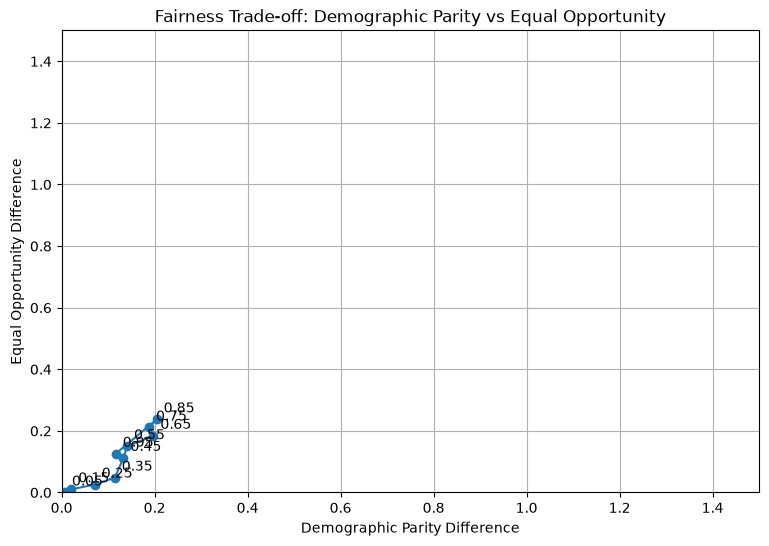

In [93]:
# Phase 8.2 – DP vs EO fairness trade-off chart

plt.figure(figsize=(9, 6))

plt.plot(
    fairness_results["DP_Difference"],
    fairness_results["EO_Difference"],
    marker="o"
)

for _, row in fairness_results.iterrows():
    plt.annotate(
        f"{row['Threshold']:.2f}",
        (
            row["DP_Difference"],
            row["EO_Difference"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Demographic Parity Difference")
plt.ylabel("Equal Opportunity Difference")
plt.title("Fairness Trade-off: Demographic Parity vs Equal Opportunity")

plt.xlim(0, 1.5)
plt.ylim(0, 1.5)

plt.grid(True)
plt.show()

In [94]:
# Phase 8.3 – Identify minimum fairness gaps

min_dp = fairness_results.loc[
    fairness_results["DP_Difference"].idxmin()
]

min_eo = fairness_results.loc[
    fairness_results["EO_Difference"].idxmin()
]

min_pp = fairness_results.loc[
    fairness_results["PP_Difference"].idxmin()
]

print("Threshold with minimum DP difference:")
print(min_dp)

print("\nThreshold with minimum EO difference:")
print(min_eo)

print("\nThreshold with minimum PP difference:")
print(min_pp)

Threshold with minimum DP difference:
Threshold        0.050000
DP_Difference    0.007353
EO_Difference    0.000000
PP_Difference    0.015989
Name: 0, dtype: float64

Threshold with minimum EO difference:
Threshold        0.050000
DP_Difference    0.007353
EO_Difference    0.000000
PP_Difference    0.015989
Name: 0, dtype: float64

Threshold with minimum PP difference:
Threshold        0.050000
DP_Difference    0.007353
EO_Difference    0.000000
PP_Difference    0.015989
Name: 0, dtype: float64


In [95]:
# Final Results Summary – Part 2

final_results_summary = pd.DataFrame({
    "Analysis": [
        "Test Set Size",
        "Linear vs Logistic Mismatches",
        "Mismatch Percentage",
        "High-Confidence Wrong Cases",
        "Adversarial Percentage",
        "Adversarial Mean Age",
        "Test Set Mean Age",
        "Adversarial False Positives",
        "Adversarial False Negatives",
        "Minimum DP Difference",
        "Minimum EO Difference",
        "Minimum PP Difference"
    ],
    "Result": [
        300,
        76,
        "25.33%",
        29,
        "9.67%",
        39.93,
        35.60,
        21,
        8,
        0.007353,
        0.000000,
        0.015989
    ]
})

display(final_results_summary)

,Analysis,Result
0,Test Set Size,300
1,Linear vs Logistic Mismatches,76
2,Mismatch Percentage,25.33%
3,High-Confidence Wrong Cases,29
4,Adversarial Percentage,9.67%
5,Adversarial Mean Age,39.93
6,Test Set Mean Age,35.6
7,Adversarial False Positives,21
8,Adversarial False Negatives,8
9,Minimum DP Difference,0.007353
